# Setup

We traine a one-layer RNN for the following task: given a sequence of SEQ_LEN  real numbers, we solve the SEQ_LEN-way classification task of outputting the argmax.

Train data is iid sampled from $\text{Unif}(-1,1)^{10}$, so each number in a sequence is also independent.


In [ ]:
%load_ext autoreload
%autoreload 2

import asyncio
from os.path import dirname, abspath
import sys, os
d = dirname(os.path.abspath(''))
sys.path.append(d)

import torch
from torch.utils.data import Dataset, TensorDataset, DataLoader
import torch.nn as nn
import torch.nn.functional as F
device = torch.device('cpu')
print('using ' + str(device))

import numpy as np
import pandas as pd
from tqdm.auto import trange, tqdm
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()

# np.random.seed(123)
torch.set_printoptions(precision=2)
np.set_printoptions(precision=2)
%matplotlib inline

from IPython.display import display
from tqdm.notebook import tqdm as tqdm_notebook
from ipywidgets import Output

from sklearn.manifold import TSNE

# Each entry of each sequence is generated from U(-1,1).
SAMPLES = 50000
SEQ_LEN = 10
DIM = 1

def relu(x):
    return np.maximum(0, x)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
using cpu


## Model definitions

In [ ]:
class OneLayerRNN(nn.Module):
    def __init__(self, hidden_size):
        super(OneLayerRNN, self).__init__()
        self.rnn = nn.RNN(input_size=DIM, hidden_size=hidden_size, batch_first=True, nonlinearity='relu')
        self.linear = nn.Linear(hidden_size, SEQ_LEN)

    def forward(self, x, init_state=None):
        outputs, h_n = self.rnn(x, init_state)
        return self.linear(outputs), self.linear(h_n.squeeze(0))


class OneLayerRNNNoBias(nn.Module):
    def __init__(self, hidden_size):
        super(OneLayerRNNNoBias, self).__init__()
        self.rnn = nn.RNN(input_size=DIM, hidden_size=hidden_size, batch_first=True, nonlinearity='relu', bias=False)
        self.linear = nn.Linear(hidden_size, SEQ_LEN, bias=False)

    def forward(self, x, init_state=None):
        outputs, h_n = self.rnn(x, init_state)
        return self.linear(outputs), self.linear(h_n.squeeze(0))


class LinearRNNCell(nn.Module):
    def __init__(self, input_size, hidden_size, bias=True):
        super(LinearRNNCell, self).__init__()
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.bias = bias
        self.weight_ih = nn.Parameter(torch.Tensor(hidden_size, input_size))
        self.weight_hh = nn.Parameter(torch.Tensor(hidden_size, hidden_size))
        if self.bias:
            self.bias_ih = nn.Parameter(torch.Tensor(hidden_size))
            self.bias_hh = nn.Parameter(torch.Tensor(hidden_size))
        self.init_weights()

    def init_weights(self):
        stdv = 1.0 / self.hidden_size ** 0.5
        for weight in self.parameters():
            nn.init.uniform_(weight, -stdv, stdv)

    def forward(self, input, hidden):
        if self.bias:
            return torch.addmm(self.bias_ih, input, self.weight_ih.t()) + torch.addmm(self.bias_hh, hidden,
                                                                                      self.weight_hh.t())
        else:
            return torch.mm(input, self.weight_ih.t()) + torch.mm(hidden, self.weight_hh.t())


class OneLayerLinearRNN(nn.Module):
    def __init__(self, hidden_size, input_size=DIM, seq_len=SEQ_LEN, bias=True):
        super(OneLayerLinearRNN, self).__init__()
        self.hidden_size = hidden_size
        self.seq_len = seq_len
        # Initialize the RNN cell with or without bias
        self.rnn = LinearRNNCell(input_size, hidden_size, bias=bias)
        # Initialize the linear layer with or without bias
        self.linear = nn.Linear(hidden_size, seq_len, bias=bias)

    def forward(self, x, init_state=None):
        h_t = init_state or torch.zeros(x.size(0), self.hidden_size, dtype=x.dtype, device=x.device)
        outputs = []

        for t in range(self.seq_len):  # Assuming x is already batched and sequenced
            h_t = self.rnn(x[:, t, :], h_t)
            outputs.append(h_t.unsqueeze(1))

        outputs = torch.cat(outputs, dim=1)
        # Apply the linear layer to the sequence of outputs
        seq_output = self.linear(outputs)
        # Apply the linear layer to the last hidden state
        last_output = self.linear(h_t)
        return seq_output, last_output

    def equiv_linear_func(self, x, init_state=None):
        # Assuming DIM = 1, the linear RNN is equivalent to a linear transform of input Ax + b, this function returns A and b
        assert DIM == 1

        # Extract weights and biases
        W_hh = self.rnn.weight_hh  # Weight matrix for hidden to hidden
        W_ih = self.rnn.weight_ih  # Weight matrix for input to hidden
        b_ih = self.rnn.bias_ih if self.rnn.bias else 0  # Bias for input to hidden
        b_hh = self.rnn.bias_hh if self.rnn.bias else 0  # Bias for hidden to hidden
        W_ho = self.linear.weight  # Weight matrix for hidden to output
        b_oh = self.linear.bias if self.linear.bias is not None else 0  # Bias for hidden to output

        # Compute the equivalent weight vector w = W_ih for DIM = 1
        w = W_ih

        # Compute the equivalent A matrix
        A_h = torch.zeros(self.seq_len, self.seq_len)
        for i in range(self.seq_len):
            A_h[:, i] = (torch.matrix_power(W_hh, self.seq_len - 1 - i) @ w).squeeze()
        A = W_ho @ A_h

        # Compute the equivalent b vector
        b = torch.zeros(self.seq_len)
        for i in range(self.seq_len):
            b += torch.matrix_power(W_hh, i) @ (b_ih + b_hh)
        if init_state is not None:
            b += torch.matrix_power(W_hh, self.seq_len) @ init_state
        b = W_ho @ b + b_oh

        return A, b



## Training

In [ ]:
def make_data_arg2ndmax(samples, seq_len, dim, device, factor=1):
    src = torch.rand(samples, seq_len, dim, device=device)*2*factor - factor
    y = src.sort(dim = 1)[1][:,-2].squeeze()
    return src, y

def make_data_argmax(samples, seq_len, dim, device, factor=1):
    src = torch.rand(samples, seq_len, dim, device=device)*2*factor - factor
    y = src.sort(dim = 1)[1][:,-1].squeeze()
    return src, y


# This training code is not efficient
def train_with_fresh_data(model, epochs, lr, weight_decay, samples_per_batch, device, total_samples_per_epoch=100000, make_data=make_data_arg2ndmax):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=0.995)

    losses = []
    val_losses = []
    accs = []
    val_accs = []

    model.train()
    pbar = tqdm_notebook(total=epochs, desc='Training progress')
    plot_output = Output()  # Create an output widget for plots
    display(plot_output)  # Display it below the progress bar


    for epoch in range(epochs):
        model.train()
        total_loss = 0
        correct = 0
        total = 0

        # Number of training steps per epoch
        steps_per_epoch = total_samples_per_epoch // samples_per_batch

        for step in range(steps_per_epoch):
            src_batch, y_batch = make_data(samples_per_batch, SEQ_LEN, DIM, device, 1)
            _, pred_train = model(src_batch)
            loss_train = F.cross_entropy(pred_train, y_batch)
            optimizer.zero_grad()
            loss_train.backward()
            optimizer.step()

            total_loss += loss_train.item()
            correct += (pred_train.argmax(dim=1) == y_batch).sum().item()
            total += y_batch.size(0)

        average_loss = total_loss / steps_per_epoch
        training_accuracy = correct / total
        losses.append(average_loss)
        accs.append(training_accuracy)

        scheduler.step()

        # Update progress bar
        pbar.set_postfix(lr=scheduler.get_last_lr()[0], loss=average_loss, acc=training_accuracy)
        pbar.update(1)
        if epoch >= 1:  # Update plots after each epoch
            with plot_output:
                plt.figure(figsize=(12, 5))

                # Training and Validation Loss
                plt.subplot(1, 2, 1)
                plt.plot(losses, label='Training Loss')
                # plt.plot(val_losses, label='Validation Loss', linestyle='--')
                plt.legend()
                plt.xlabel('Epochs')
                plt.ylabel('Loss')
                plt.title('Loss')

                # Training and Validation Accuracy
                plt.subplot(1, 2, 2)
                plt.plot(accs, label='Training Accuracy')
                # plt.plot(val_accs, label='Validation Accuracy', linestyle='--')
                plt.legend()
                plt.xlabel('Epochs')
                plt.ylabel('Accuracy')
                plt.title('Accuracy')

                plt.tight_layout()
                display(plt.gcf())  # Display current figure inside the Output widget
                plt.close()  # Close the matplotlib plot to prevent it from being displayed outside the Output widget
                plot_output.clear_output(wait=True)  # Clear the output for the next epoch's plots

    pbar.close()
    return losses, accs


In [ ]:

EPOCHS = 1000
LR = 0.005
WEIGHT_DECAY = 1e-14

one_layer_rnn = OneLayerRNNNoBias(hidden_size=16)
models = {
    '1LayerRNNNoBias': one_layer_rnn,
}


# for name, model in models.items():
#     print(f"Model: {name}")
#     train_with_fresh_data(model, epochs=EPOCHS, lr=LR, weight_decay=WEIGHT_DECAY, samples_per_batch=batch_size, device=device)



## Model loading

In [ ]:
# can download the model here:  https://drive.google.com/file/d/137WbqDdEr7bREjykM9ZpPTHYTo9kBo65/view?usp=sharing
model = OneLayerRNNNoBias(hidden_size = 16)
model.load_state_dict(torch.load('one_layer_16_hidden_94_acc_2nd_argmax.pth'))
name = "16NeuronNoBias"
m = 16
d = SEQ_LEN

# Interpreting the model

In this section, we provide a bit mechanistic explanation of the models

## Accuracy

In [ ]:
def arg2ndmax_accuracy(w_ih, w_hh, w_oh):
    num_samples = 100000
    accuracy = 0

    for _ in range(num_samples):
        test_x = np.random.uniform(low=-1, high=1, size=SEQ_LEN)
        h_t = np.zeros((16, 1))

        for i in range(SEQ_LEN):
            x_i = test_x[i]
            h_t = relu(w_hh @ h_t + x_i * w_ih)

        logit = w_oh @ h_t
        accuracy += (test_x.argsort()[-2] == np.argmax(logit))

    return accuracy / num_samples

def calculate_per_class_accuracy(model):
    test_x, test_y = make_data_arg2ndmax(100000, SEQ_LEN, DIM, device)
    _, logits = model(test_x)
    preds = torch.argmax(logits, dim = 1)
    per_class_accuracy = []
    for i in range(10):
        num_class_i = torch.sum(test_y == i)
        accu = torch.sum(preds[test_y == i] == test_y[test_y == i]) / num_class_i
        per_class_accuracy.append(accu.item())

    print(f"The per-class accuracy is: {per_class_accuracy}")

calculate_per_class_accuracy(model)

The per-class accuracy is: [0.9415069818496704, 0.9549974799156189, 0.955310583114624, 0.9440906047821045, 0.9437487125396729, 0.9357606172561646, 0.9310171008110046, 0.9226870536804199, 0.9167738556861877, 0.9225232601165771]


## $w_{ih}$ ablations

In [ ]:
def extract_model_weights(model):
    weight_ih = model.rnn.weight_ih_l0.detach().clone()
    weight_hh = model.rnn.weight_hh_l0.detach().clone()
    bias_ih = model.rnn.bias_ih_l0.detach().clone() if model.rnn.bias else torch.zeros(model.rnn.hidden_size)
    bias_hh = model.rnn.bias_hh_l0.detach().clone() if model.rnn.bias else torch.zeros(model.rnn.hidden_size)
    weight_oh = model.linear.weight.detach().clone()
    bias_oh = model.linear.bias.detach().clone() if model.linear.bias is not None else torch.zeros(model.linear.out_features)

    # Convert tensors to numpy only where necessary for correlation or external libraries
    w_oh = weight_oh.cpu().numpy()
    b_h = (bias_ih + bias_hh).view(-1, 1).cpu().numpy()
    w_ih = weight_ih.cpu().numpy()
    w_hh = weight_hh.cpu().numpy()

    return w_ih, b_h, w_hh, w_oh

def extract_model_weights_with_ablation_and_scaling(model):
    weight_ih = model.rnn.weight_ih_l0.detach().clone()
    weight_hh = model.rnn.weight_hh_l0.detach().clone()
    bias_ih = model.rnn.bias_ih_l0.detach().clone() if model.rnn.bias else torch.zeros(model.rnn.hidden_size)
    bias_hh = model.rnn.bias_hh_l0.detach().clone() if model.rnn.bias else torch.zeros(model.rnn.hidden_size)
    weight_oh = model.linear.weight.detach().clone()
    bias_oh = model.linear.bias.detach().clone() if model.linear.bias is not None else torch.zeros(model.linear.out_features)

    # Convert tensors to numpy only where necessary for correlation or external libraries
    w_oh = weight_oh.cpu().numpy()
    b_h = (bias_ih + bias_hh).view(-1, 1).cpu().numpy()
    w_ih = weight_ih.cpu().numpy()
    w_hh = weight_hh.cpu().numpy()

    # The following ablation does not really affect the accuracy
    w_ih = np.where(np.abs(w_ih) < 0.1, 0, w_ih) # no accuracy drop
    w_hh = np.where(np.abs(w_hh) < 0.005, 0, w_hh)

    # The following cause 3% accuracy drop
    # input_neurons = [1, 4, 6, 7, 8, 14]
    # for index in range(m):
    #     if index not in input_neurons:
    #         w_ih[index,:] = 0

    # The following ablations decreases the model accuracy
    # w_hh = np.where(np.abs(w_hh) < 0.01, 0, w_hh)
    # w_hh[:,9] = 0


    return w_ih, b_h, w_hh, w_oh


w_ih, b_h, w_hh, w_oh = extract_model_weights(model)
arg2ndmax_accuracy(w_ih, w_hh, w_oh)


0.93792

In [ ]:
# We looking at accuracy drop caused by setting each neuron input weight to 0
# This shows marginally neurons (1, 4, 6 ,7, 8) are indeed the major input neurons

def input_weight_ablation(model, index):
    weight_ih = model.rnn.weight_ih_l0.detach().clone()
    weight_hh = model.rnn.weight_hh_l0.detach().clone()
    bias_ih = model.rnn.bias_ih_l0.detach().clone() if model.rnn.bias else torch.zeros(model.rnn.hidden_size)
    bias_hh = model.rnn.bias_hh_l0.detach().clone() if model.rnn.bias else torch.zeros(model.rnn.hidden_size)
    weight_oh = model.linear.weight.detach().clone()
    bias_oh = model.linear.bias.detach().clone() if model.linear.bias is not None else torch.zeros(model.linear.out_features)

    # Convert tensors to numpy only where necessary for correlation or external libraries
    w_oh = weight_oh.cpu().numpy()
    b_h = (bias_ih + bias_hh).view(-1, 1).cpu().numpy()
    w_ih = weight_ih.cpu().numpy()
    w_hh = weight_hh.cpu().numpy()

    w_ih[index,:] = 0

    return arg2ndmax_accuracy(w_ih, w_hh, w_oh)

ablation_accuracies = []

for index in range(m):
    ablation_accuracies.append(input_weight_ablation(model, index))
print(ablation_accuracies)




[0.93812, 0.15397, 0.93737, 0.93777, 0.18228, 0.92804, 0.15089, 0.12008, 0.20156, 0.93207, 0.93833, 0.93522, 0.92956, 0.93808, 0.85871, 0.93791]


## Model weights visualization

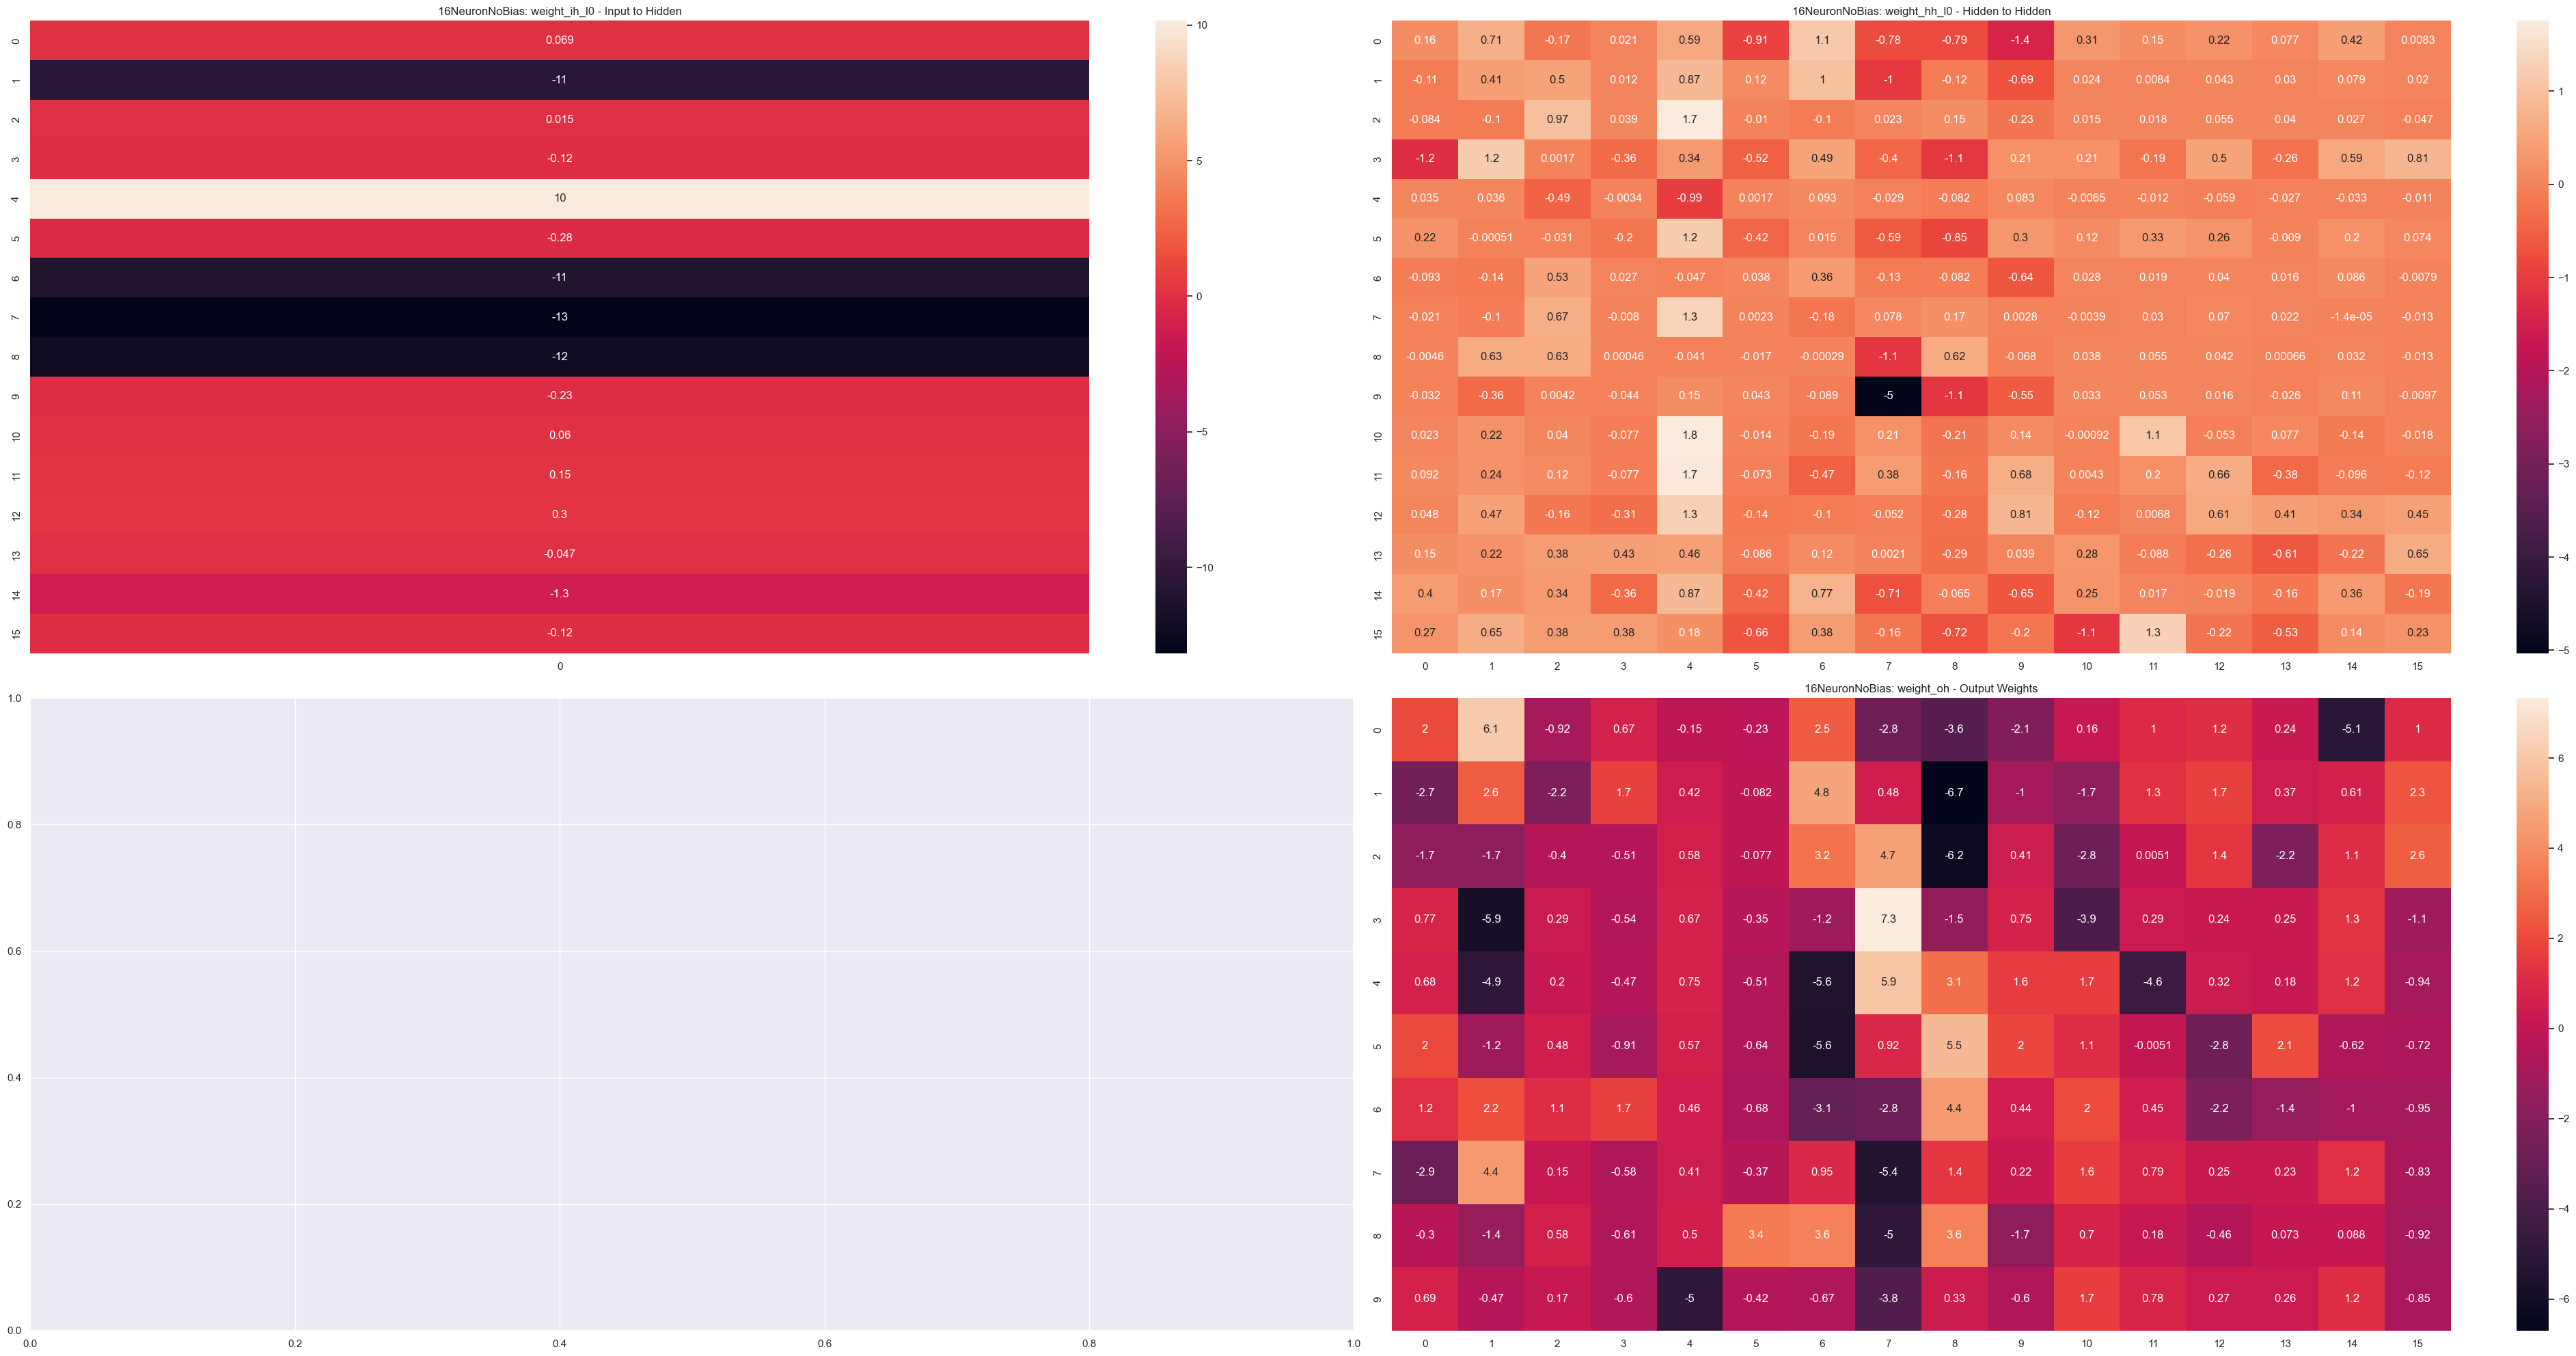

In [ ]:
# Compute powers of w_hh and multiply by w_ih using numpy
w_hh_powers = [np.linalg.matrix_power(w_hh, k) for k in range(SEQ_LEN + 1)]
w_hh_w_ih = [w_oh @ power for power in w_hh_powers]


excluded_indices = [1, 2, 4, 6, 7, 8, 14]
filtered_indices = range(16)

# Visualizations
fig, axarr = plt.subplots(2, 2, figsize=(40, 20))

sns.heatmap(w_ih, ax=axarr[0, 0], cbar=True, annot=True)
axarr[0, 0].set_title(f"{name}: weight_ih_l0 - Input to Hidden")

sns.heatmap(w_hh, ax=axarr[0, 1], cbar=True, annot=True)
axarr[0, 1].set_title(f"{name}: weight_hh_l0 - Hidden to Hidden")

sns.heatmap(w_oh, ax=axarr[1, 1], cbar=True, annot=True)
axarr[1, 1].set_title(f"{name}: weight_oh - Output Weights")

# sns.heatmap(np.corrcoef(w_oh), cmap='coolwarm', ax=axarr[2, 0], vmin=-1, vmax=1, annot=True, linewidths=0.5, cbar_kws={"shrink": 0.75})
# axarr[2, 0].set_title(name + ": w_oh correlation")

plt.tight_layout()
plt.show()

The sum of each col of w_oh is: [-0.23 -0.3  -0.58 -0.17 -0.78  0.05 -1.08 -0.53  0.42 -0.04  0.63  0.21
 -0.09  0.07 -0.03 -0.42]
The singular values are: [19.2  17.92  8.64  6.15  5.97  4.6   3.42  2.4   2.31  0.31]
The singular values are: [24.85 19.09 14.3   8.31  6.09  4.6   3.43  2.4   2.31]


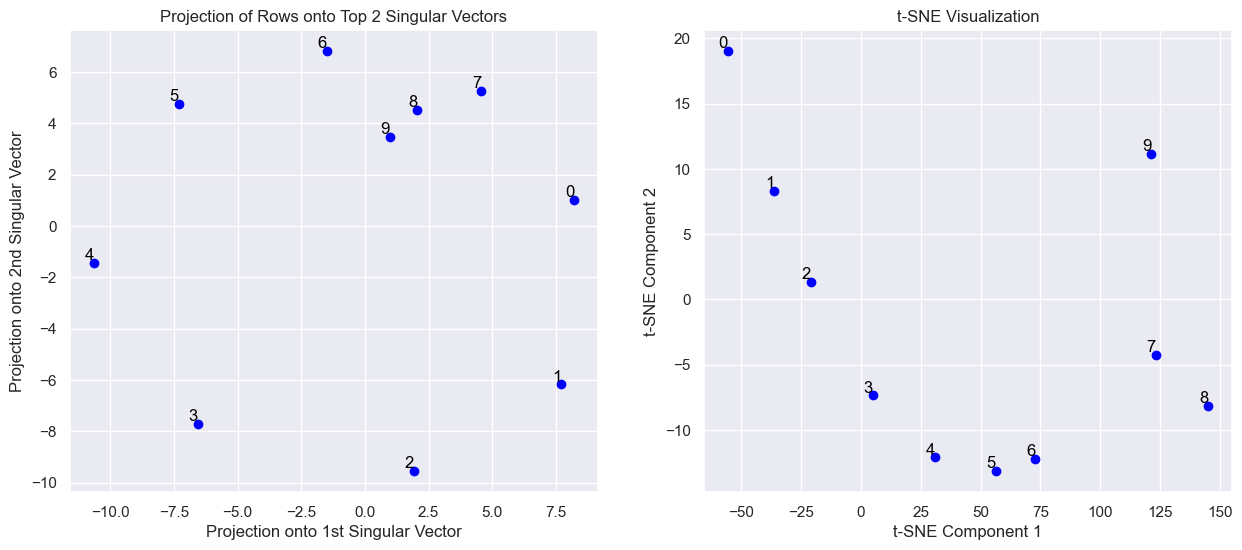

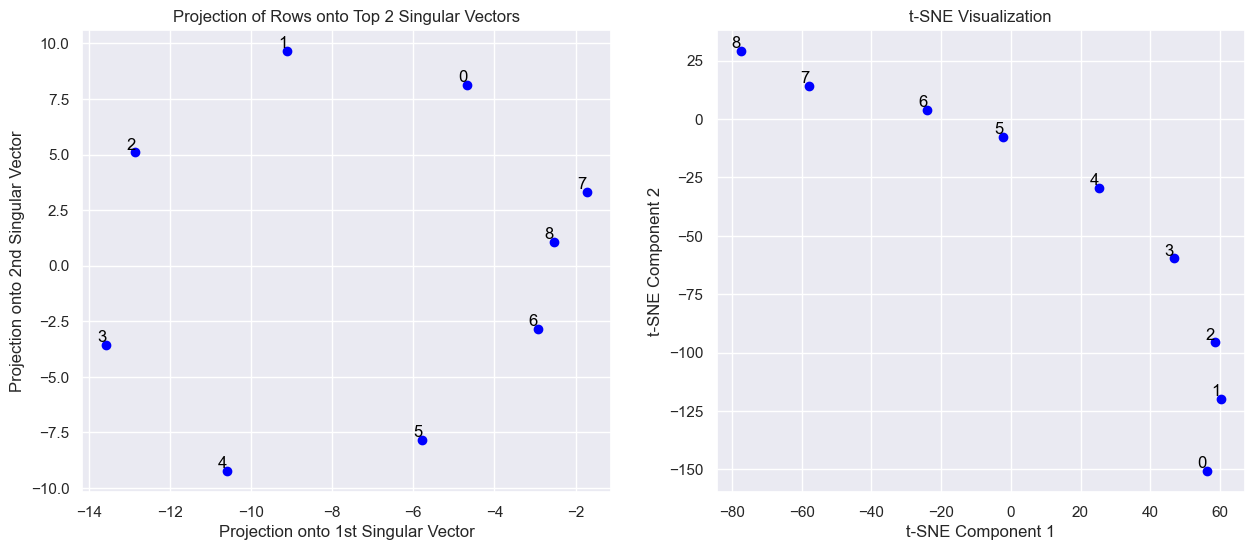

In [ ]:
# This model didn't use large enough WD, otherwise we should expect to see the weights are 0
print("The sum of each col of w_oh is:", w_oh.sum(axis = 0))

# Two ways of visualization in 2d: SVD and TSNE
def visualization_2d(mat):
    nrows = mat.shape[0]
    U, S, Vt = np.linalg.svd(mat)
    print("The singular values are:", S)  # Display singular values
    top_2_vectors = Vt[:2, :]  # Top 2 singular vectors from Vt (transpose of V)
    projection = mat @ top_2_vectors.T  # Project onto the top 2 singular vectors

    plt.figure(figsize=(15, 6))
    plt.subplot(1, 2, 1)  # Left plot in a 1x2 grid
    for i, (x, y) in enumerate(projection):
        plt.scatter(x, y, color='blue', marker='o')
        plt.text(x, y, f'{i}', color='black', fontsize=12, ha='right', va='bottom')
    plt.xlabel('Projection onto 1st Singular Vector')
    plt.ylabel('Projection onto 2nd Singular Vector')
    plt.title('Projection of Rows onto Top 2 Singular Vectors')
    plt.grid(True)

    tsne = TSNE(n_components=2, learning_rate='auto', init='random', perplexity=2)
    tsne_results = tsne.fit_transform(mat)
    tsne_df = pd.DataFrame(tsne_results, columns=['TSNE1', 'TSNE2'])

    plt.subplot(1, 2, 2)  # Right plot in a 1x2 grid
    for i in range(len(tsne_df)):
        plt.scatter(tsne_df.loc[i, 'TSNE1'], tsne_df.loc[i, 'TSNE2'], color='blue', marker='o')
        plt.text(tsne_df.loc[i, 'TSNE1'], tsne_df.loc[i, 'TSNE2'], str(i), color='black', fontsize=12, ha='right', va='bottom')
    plt.xlabel('t-SNE Component 1')
    plt.ylabel('t-SNE Component 2')
    plt.title('t-SNE Visualization')
    plt.grid(True)

w_oh_differences = w_oh[:9, :] - w_oh[9, :]

proj_on_top2_singular_vecs(w_oh)
proj_on_top2_singular_vecs(w_oh_differences)

## More weight visualization analysis



    

### $W_{hh}$

We separate the neurons into two groups, input neurons (1,4,6,7,8) along with neuron 2 which is closely related to neuron 4 and 7, and all other neurons as the other group.


[1, 2, 4, 6, 7, 8, 0, 3, 5, 9, 10, 11, 12, 13, 14, 15]


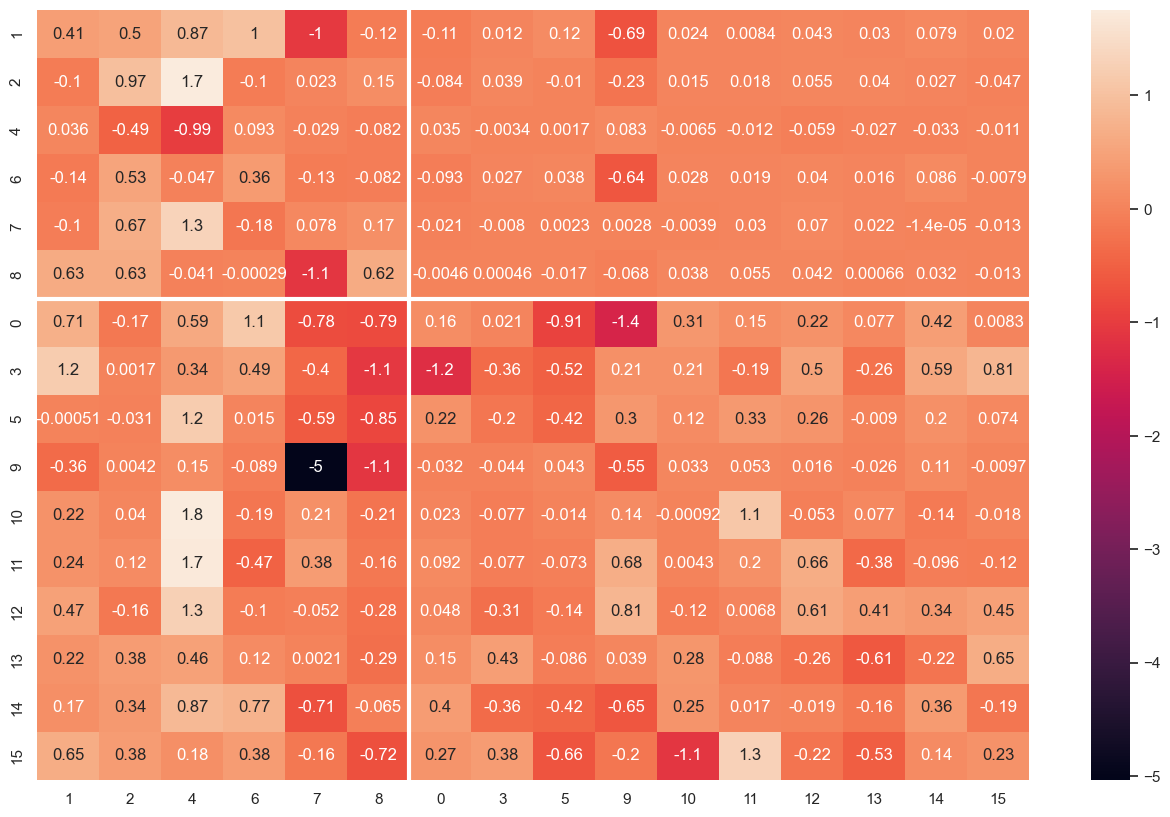

In [ ]:
excluded_indices = [1, 2, 4, 6, 7, 8]
filtered_indices = [x for x in range(16) if x not in excluded_indices]
new_order_indices = excluded_indices + filtered_indices
print(new_order_indices)
w_hh_reorder = w_hh[np.ix_(new_order_indices, new_order_indices)]

plt.figure(figsize=(16, 10))
ax = sns.heatmap(w_hh_reorder,
                 cbar=True,
                 annot=True,
                 xticklabels=new_order_indices,
                 yticklabels=new_order_indices)
ax.axhline(y=len(excluded_indices), color='white', lw=3)
ax.axvline(x=len(excluded_indices), color='white', lw=3)
plt.xticks();
plt.yticks();

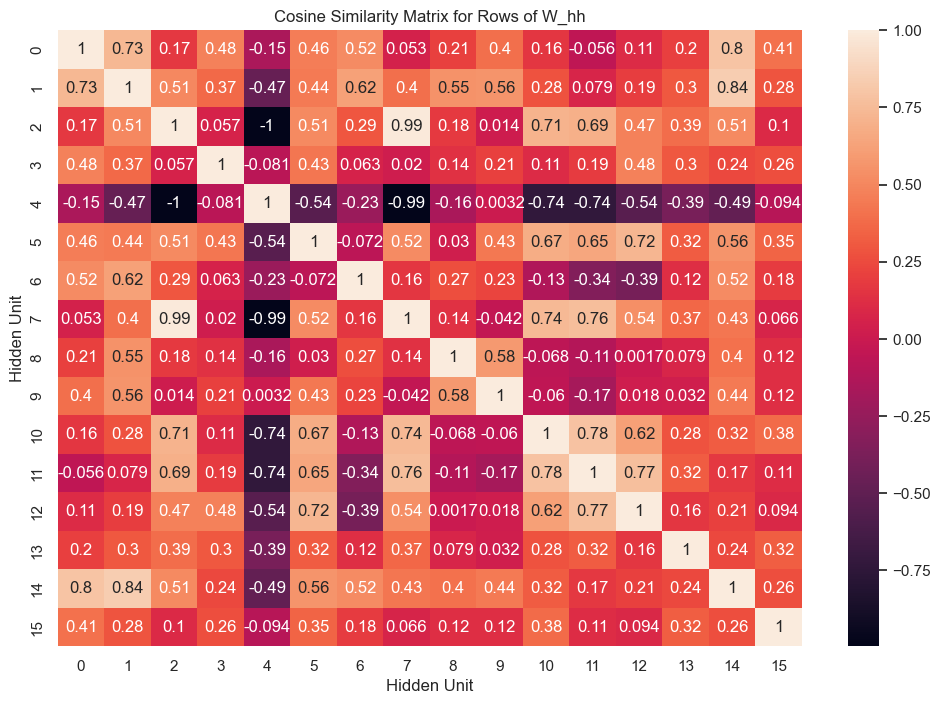

In [ ]:
# Compute the cosine similarity matrix
cosine_similarity_matrix = np.zeros((w_hh.shape[0], w_hh.shape[0]))
for i in range(w_hh.shape[0]):
    for j in range(w_hh.shape[0]):
        cosine_similarity_matrix[i, j] = np.dot(w_hh[i, :], w_hh[j, :]) / (np.linalg.norm(w_hh[i, :]) * np.linalg.norm(w_hh[j, :]))

# Visualize the cosine similarity matrix
plt.figure(figsize=(12, 8))
sns.heatmap(cosine_similarity_matrix, annot=True)
plt.xlabel('Hidden Unit')
plt.ylabel('Hidden Unit')
plt.title('Cosine Similarity Matrix for Rows of W_hh')
plt.show()


### $W_{hh}$ and $W_{oh}$

Text(0.5, 1.0, 'Correlation between w_oh and w_oh w_hh, excluding 9 and []')

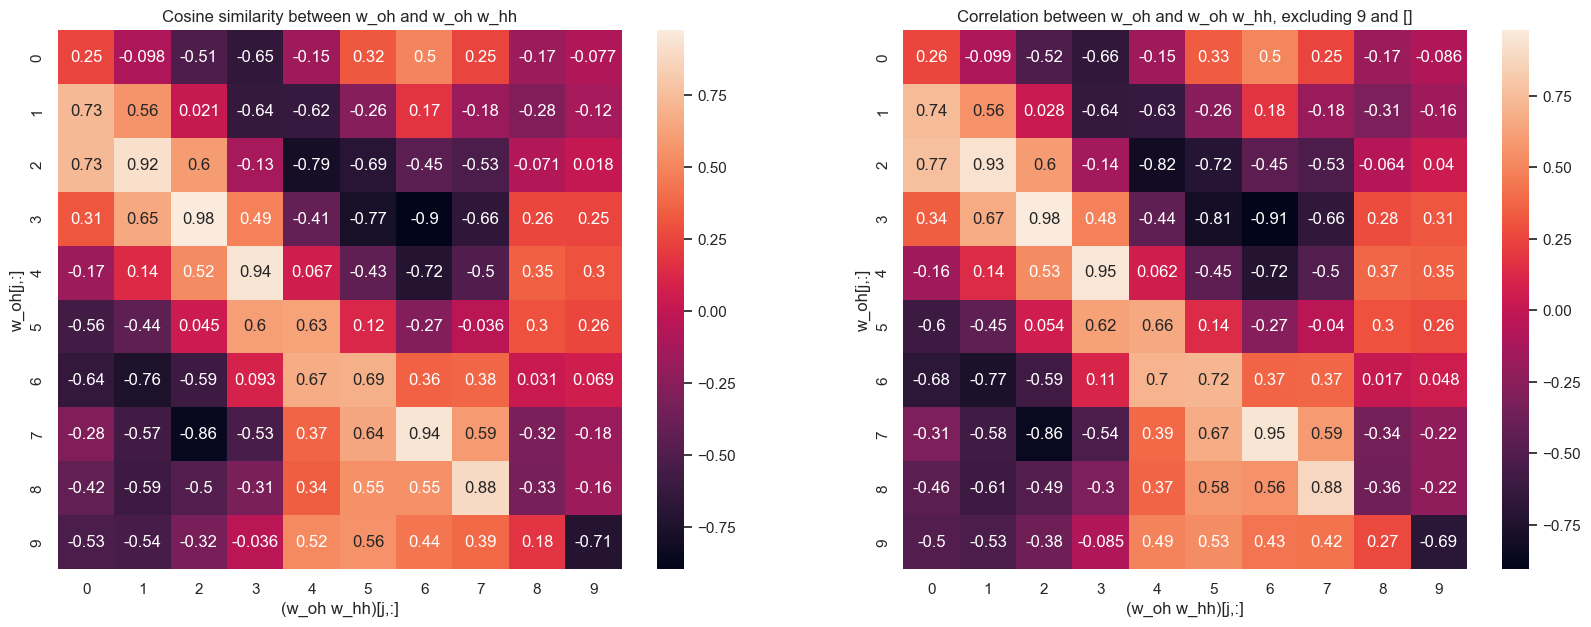

In [ ]:
from sklearn.metrics.pairwise import cosine_similarity

excluded_indices = []
filtered_indices = [x for x in range(16) if x not in excluded_indices]

_, axarr = plt.subplots(1, 2, figsize=(20, 7))

rotation_correlations = np.array([
    [np.corrcoef((w_oh @ w_hh)[i, excluded_indices + filtered_indices], w_oh[j, excluded_indices + filtered_indices])[0, 1] for i in range(SEQ_LEN)]
    for j in range(SEQ_LEN)
])

# shifting correlation
shifting_simiarity = np.array([
    [cosine_similarity(
        (w_oh @ w_hh)[i, :].reshape(1,-1),
        w_oh[j, :].reshape(1,-1)
     )[0][0] for i in range(d)]
    for j in range(d)
])

sns.heatmap(shifting_simiarity, ax = axarr[0], cbar=True, annot=True)
axarr[0].set_ylabel('w_oh[j,:]')
axarr[0].set_xlabel('(w_oh w_hh)[j,:]')
axarr[0].set_title('Cosine similarity between w_oh and w_oh w_hh')


sparse_rotation_correlations = np.array([
    [np.corrcoef((w_oh[:, filtered_indices] @ w_hh[np.ix_(filtered_indices, filtered_indices)])[i, :], w_oh[j, filtered_indices])[0, 1] for i in range(SEQ_LEN)]
    for j in range(SEQ_LEN)
])
sns.heatmap(sparse_rotation_correlations, ax = axarr[1], cbar=True, annot=True)
axarr[1].set_ylabel('w_oh[j,:]')
axarr[1].set_xlabel('(w_oh w_hh)[j,:]')
axarr[1].set_title(f'Correlation between w_oh and w_oh w_hh, excluding 9 and {excluded_indices}')

# the rotation tends to overshoot a bit, so Av_k = 1.1 v_{k-1} or something
# for i in range(8):
#     print(np.linalg.norm((w_oh[:, filtered_indices] @ w_hh[np.ix_(filtered_indices, filtered_indices)])[i, :]))
#     print(np.linalg.norm(w_oh[i+1,filtered_indices]))
#     print((w_oh[:, filtered_indices] @ w_hh[np.ix_(filtered_indices, filtered_indices)])[i, :].dot(w_oh[i+1,filtered_indices]))
#     print("----")

## Logit functions and neurons functions

In [ ]:
def logit_analysis(test_x, w_ih, w_hh, w_oh, verbose = True):

    print(test_x.squeeze())
    W_hh_h_t_history = np.zeros((d, m))
    hidden_states = np.zeros((d, m))
    logits = np.zeros((d,d))
    h_t = np.zeros((m, 1))

    for i in range(d):
        x_i = test_x.squeeze()[i].item()
        W_hh_h_t = w_hh @ h_t
        W_hh_h_t_history[i, :] = W_hh_h_t.squeeze()
        h_t = relu(W_hh_h_t + + x_i * w_ih)
        hidden_states[i,:] = h_t.squeeze()

        logits[i] = (w_oh @ h_t).squeeze()

    _, axarr = plt.subplots(1, 3, figsize=(20, 5))

    sns.heatmap(logits, ax=axarr[0], annot = True ,cbar = False)
    axarr[0].set_ylabel('Sequence')
    axarr[0].set_xlabel('Logit')

    sns.heatmap(hidden_states, ax=axarr[1], annot = True, cbar = False, yticklabels=[f"Step {i}" for i in range(d)])
    axarr[1].set_xlabel('Neuron Index')
    axarr[1].set_ylabel('Sequence index')

    sns.heatmap(W_hh_h_t_history, ax=axarr[2], annot = True, cbar = False, yticklabels=[f"Step {i}" for i in range(d)])
    axarr[2].set_xlabel('w_hh @ h_{t-1} Neuron Index')
    axarr[2].set_ylabel('Sequence index')


    plt.tight_layout()
    plt.show()


def logit_visualization(w_ih, w_hh, w_oh, test_x, perturb_idx, seq_idx, logit_indices):
    grid = [-1.0 + 0.001 * x for x in range(2001)]
    values = {logit_idx:[] for logit_idx in logit_indices}
    for x in grid:
        test_x[0, perturb_idx] = x

        h_t = np.zeros((m, 1))
        for i in range(seq_idx + 1):
            x_i = test_x.squeeze()[i].item()
            h_t = relu(w_hh @ h_t + x_i * w_ih)
        logits = w_oh @ h_t
        for logit_idx in logit_indices:
            values[logit_idx].append(logits[logit_idx])


    for logit_idx in logit_indices:
        plt.plot(grid, values[logit_idx], label = f'logit[{logit_idx}]')
        label_x_position = grid[1]  # X position for the label
        label_y_position = values[logit_idx][1]  # Y position for the label
        # Place the label. Adjust `ha` and `va` for better alignment.
        plt.text(label_x_position, label_y_position, f'logit[{logit_idx}]', ha='right', va='bottom')
    plt.xlabel(f'x_{seq_idx}')
    plt.ylabel(f'logits')

    plt.title(f'Varying the seq_idx {seq_idx} of {test_x.squeeze()})')
    plt.legend()
    plt.show()

def hidden_state_visualization(w_ih, w_hh, w_oh, test_x, perturb_idx, seq_idx, neuron_indices):
    grid = [-1.0 + 0.001 * x for x in range(2001)]
    values = {neuron_idx:[] for neuron_idx in neuron_indices}

    print(f"seq_idx = {seq_idx}")
    for x in grid:
        test_x[0, perturb_idx] = x
        h_t = np.zeros((m, 1))

        for i in range(seq_idx + 1):
            x_i = test_x.squeeze()[i].item()
            h_t = relu(w_hh @ h_t + x_i * w_ih)

        for neuron_idx in neuron_indices:
            values[neuron_idx].append(h_t.squeeze()[neuron_idx].item())

    for neuron_idx in neuron_indices:
        plt.plot(grid, values[neuron_idx], label = f'neuron[{neuron_idx}]')
        label_x_position = grid[1]  # X position for the label
        label_y_position = values[neuron_idx][1]  # Y position for the label
        # Place the label. Adjust `ha` and `va` for better alignment.
        plt.text(label_x_position, label_y_position, f'neuron[{neuron_idx}]', ha='right', va='bottom')
    plt.xlabel(f'x_{seq_idx}')
    plt.ylabel(f'neurons')

    plt.title(f'Varying the seq_idx {seq_idx} of {test_x.squeeze()})')
    plt.legend()
    plt.show()



tensor([ 0.77,  0.90,  0.79, -0.57,  0.51,  0.32,  0.94, -0.47, -0.42, -0.66])


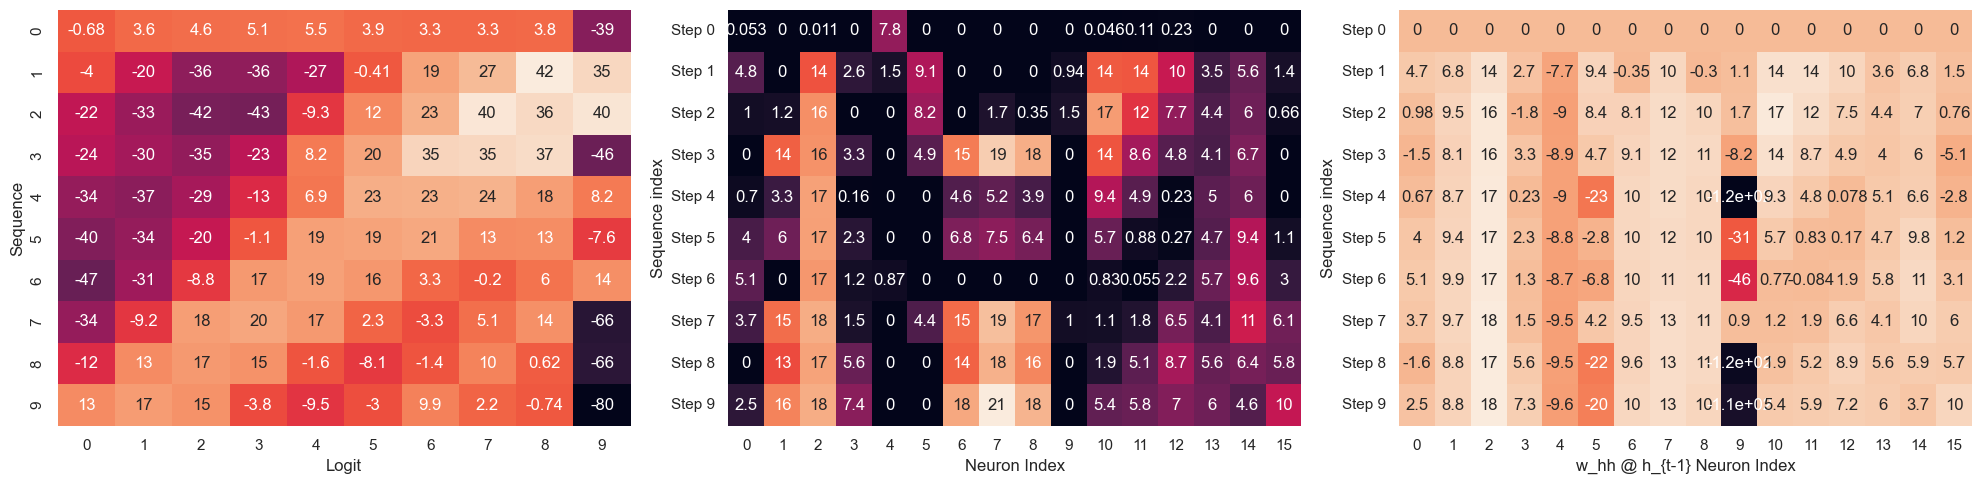

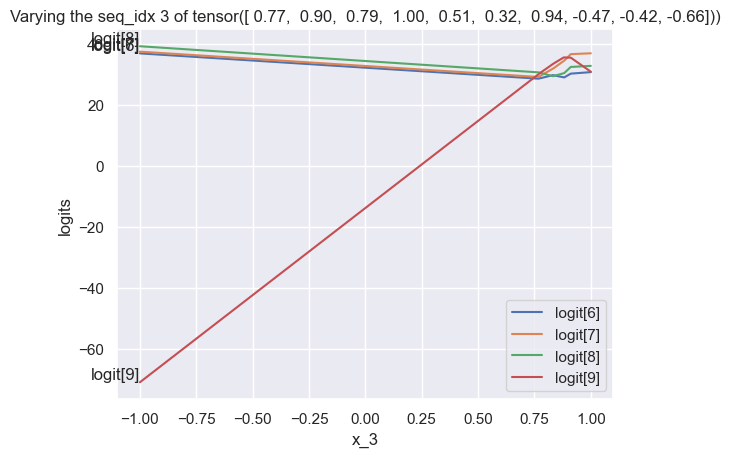

seq_idx = 3


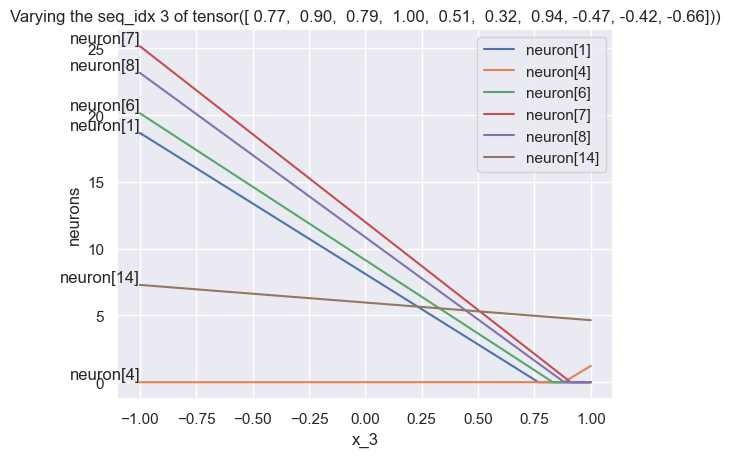

In [ ]:
# run the the following visualization with lots of different input sequence and indices for qualititative analysis

test_x = torch.FloatTensor(1, d).uniform_(-1, 1)
seq_idx = 3
perturb_idx = 3
input_neurons = [1, 4, 6, 7, 8, 14]
logit_analysis(test_x, w_ih, w_hh, w_oh)
logit_visualization(w_ih, w_hh, w_oh, test_x.clone(), perturb_idx, seq_idx, range(d-1 - seq_idx, d))
hidden_state_visualization(w_ih, w_hh, w_oh, test_x.clone(), perturb_idx, seq_idx, input_neurons)


## Identifying the Max sub-circuit

Note that at any time t, if the incoming input value xt is large enough (xt = 1), then the old running argmax becomes the running 2nd max. Neurons [1,6,7,8] will be unactivated. This implies the sub circuit excluding these neurons forms a circuit for the max and argmax tasks.

More precisely, max sub-circuit is just zeroing out a few neurons when calculating the logits. It has a decent accuracy for finding the argmax among the first d-1 numbers.


Sequence = tensor([ 0.31,  0.25,  0.50,  0.41, -0.90,  0.53, -0.78,  0.29,  0.70, -0.48])


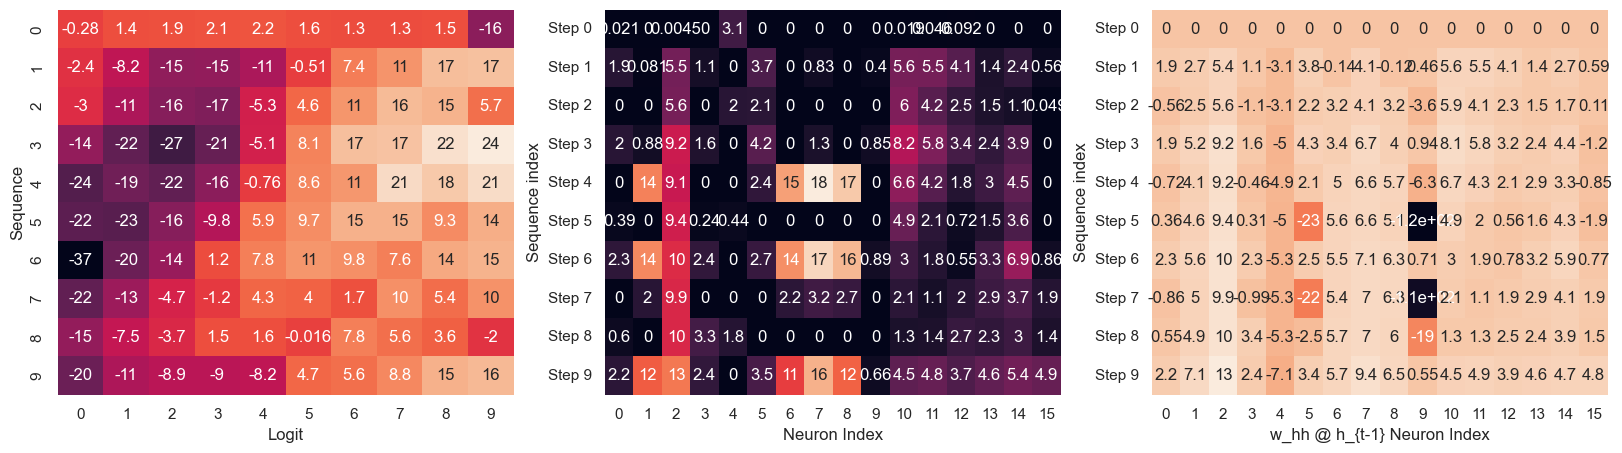

In [ ]:
def project_out(excluded_indices):
    mat = np.zeros((m, m))
    for i in range(m):
        if i not in excluded_indices:
            mat[i,i] = 1
    return mat


def max_circuit(w_ih, w_hh, w_oh, test_x, excluded_indices):

    print(f"Sequence = {test_x.squeeze()}")
    P = project_out(excluded_indices)

    W_hh_h_t_history = np.zeros((d, m))
    hidden_states = np.zeros((d, m))
    logits = np.zeros((d,d))
    h_t = np.zeros((m, 1))

    for i in range(d):
        x_i = test_x.squeeze()[i].item()
        W_hh_h_t = w_hh @ h_t
        W_hh_h_t_history[i, :] = W_hh_h_t.squeeze()
        h_t = relu(W_hh_h_t + + x_i * w_ih)
        hidden_states[i,:] = h_t.squeeze()

        logits[i] = (w_oh @ P @ h_t).squeeze()

    _, axarr = plt.subplots(1, 3, figsize=(20, 5))

    sns.heatmap(logits, ax=axarr[0], annot = True ,cbar = False)
    axarr[0].set_ylabel('Sequence')
    axarr[0].set_xlabel('Logit')

    sns.heatmap(hidden_states, ax=axarr[1], annot = True, cbar = False, yticklabels=[f"Step {i}" for i in range(d)])
    axarr[1].set_xlabel('Neuron Index')
    axarr[1].set_ylabel('Sequence index')

    sns.heatmap(W_hh_h_t_history, ax=axarr[2], annot = True, cbar = False, yticklabels=[f"Step {i}" for i in range(d)])
    axarr[2].set_xlabel('w_hh @ h_{t-1} Neuron Index')
    axarr[2].set_ylabel('Sequence index')



test_x = torch.rand(1, SEQ_LEN, DIM, device=device) * 2 - 1
# test_x = torch.tensor([0.5, 0, 0, 0.4, 0, 0, 0, 0, 0, 0], dtype=torch.float32).view(1, 10, 1)
excluded_indices = [1, 6, 7, 8]
max_circuit(w_ih, w_hh, w_oh, test_x, excluded_indices)

In [ ]:
num_samples = 10000
accuracy = 0


excluded_indices = [1, 6, 7, 8]
# excluded_indices = [1, 4, 6, 7, 8, 9] # doesn't hurt
# excluded_indices = [1, 4, 6, 7, 8, 9, 14] # hurt a bit

P = project_out(excluded_indices)

for _ in range(num_samples):
    test_x = np.random.uniform(low=-1, high=1, size=d)
    h_t = np.zeros((m, 1))

    for i in range(d):
        x_i = test_x[i]
        h_t = relu(w_hh @ h_t + x_i * w_ih)

    logit = w_oh @ P @ h_t
    accuracy += (np.argmax(logit[0:d-1]) == np.argmax(test_x[0:d-1]))

print(accuracy / num_samples)


0.8684


We calculate the argmax accuracy of this network. It has a decent accuracy for finding the argmax among the first d-1 numbers. Notably, further removing N4 or N9 doesn't hurt the accuracy. However, further removing N14 hurts the accuracy. We did not show the analysis of where the errors come from in this notebook, but a major part of the error is when the model output the 2nd argmax since the 2nd max value can be close to the max value at times.

## Individual neurons analysis

Through extensively running the logit and neurons analysis above, we have the following hypothesis that we are interested in test:

1. N2 approximately implements max_t, N4 approximately implements ReLU(x_t - max_t) and N7 approximately implements ReLU(max_t - x_t)

2. N8 represents the 2nd max value well during the earlier time steps.

3. N9 is mostly unactive.

### Probing

Instead of looking the activations values h_t, it is more reasonable to investigate pre-input neurons values W_hh @ h_t.

Given a target variable and a feature variable, there are three ways of invetigating their relationships:
1. Use x to predict y without intercept, calculate the R^2
2. Measure the correlation between (x1,...,xn) and (y1,...,yn)
3. Measure the cosine similarity between (x1,...,xn) and (y1,...yn)

Note that the correlation coefficient is the square root of the R2 with intercept, or the cosine similarity of the centered vectors. It seems that the no-intercept R2 is the best metric for our setting, since our RNN has no bias term.

In [ ]:

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.preprocessing import StandardScaler

def generate_activation_dataset(w_ih, w_hh, w_oh, num_samples=1000, seq_len = 10):
    inputs_dataset = np.zeros((num_samples, seq_len))
    activations_dataset = np.zeros((num_samples, seq_len, w_hh.shape[0]))

    for sample_index in range(num_samples):
        # can chage low = 0 or -1
        test_x = np.random.uniform(low=0, high=1, size=seq_len)
        h_t = np.zeros((w_hh.shape[0], 1))

        for time_step in range(seq_len):
            x_i = test_x[time_step]
            h_t = relu(w_hh @ h_t + x_i * w_ih)
            activations_dataset[sample_index, time_step, :] = h_t.flatten()

        inputs_dataset[sample_index, :] = test_x

    return inputs_dataset, activations_dataset


inputs_dataset, activations_dataset = generate_activation_dataset(w_ih, w_hh, w_oh)


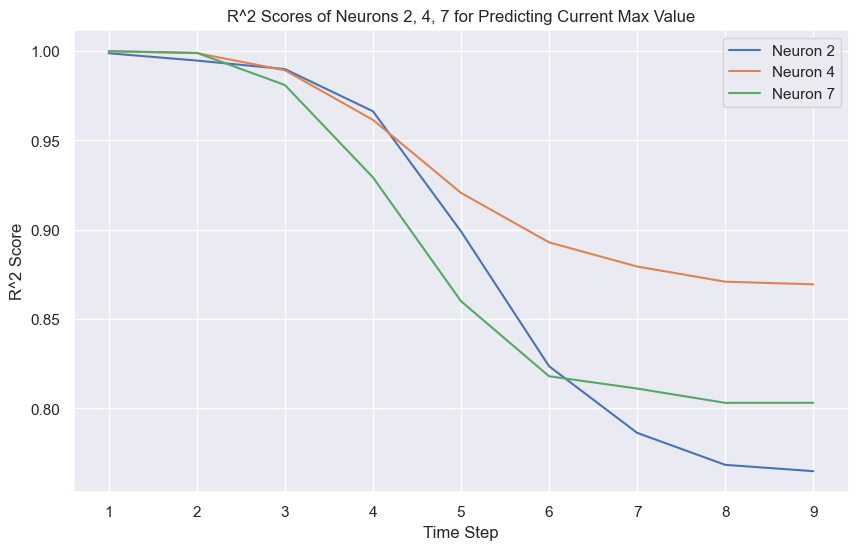

In [ ]:
neurons = [2, 4, 7]
time_steps = range(1, 10)
neuron_r2_scores = {neuron: [] for neuron in neurons}

for time_step in time_steps:
    running_max = np.max(inputs_dataset[:, :time_step+1], axis=1)
    r2_scores = []

    for k in range(w_hh.shape[0]):
        features = (activations_dataset[:, time_step, :] @ w_hh.T)[:, k].reshape(-1, 1)
        lr_model = LinearRegression(fit_intercept=False)
        lr_model.fit(features, running_max)
        predictions = lr_model.predict(features)
        r2 = r2_score(running_max, predictions)
        r2_scores.append(r2)

        if k in neurons:
            neuron_r2_scores[k].append(r2)

# Plotting the R2 scores for the specified neurons across time steps
plt.figure(figsize=(10, 6))
for neuron, scores in neuron_r2_scores.items():
    plt.plot(time_steps, scores, label=f"Neuron {neuron}")

plt.xlabel('Time Step')
plt.ylabel('R^2 Score')
plt.title('R^2 Scores of Neurons 2, 4, 7 for Predicting Current Max Value')
plt.legend()
plt.grid(True)
plt.show()

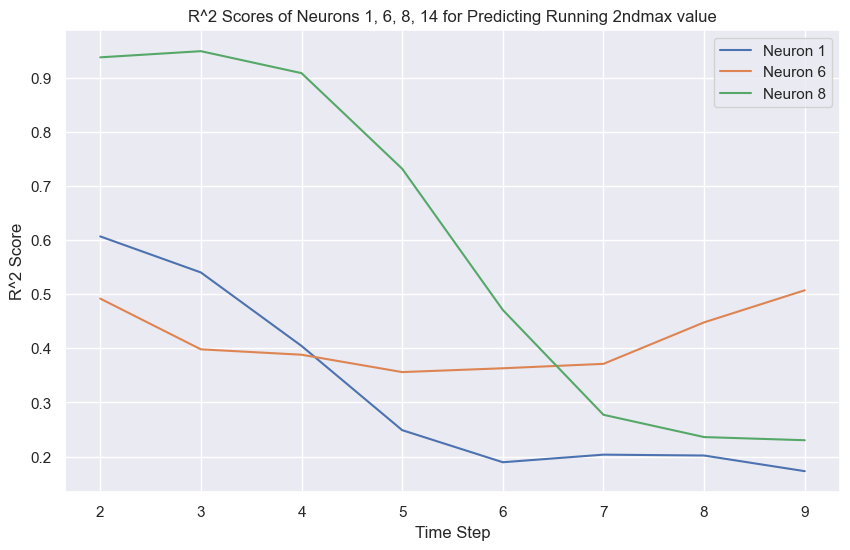

In [ ]:

neurons = [1, 6, 8]
time_steps = range(2, 10)
neuron_r2_scores = {neuron: [] for neuron in neurons}

for time_step in time_steps:
    running_2nd_max = np.sort(inputs_dataset[:, :time_step+1], axis=1)[:, -2]
    r2_scores = []

    for k in range(w_hh.shape[0]):
        features = (activations_dataset[:, time_step, :] @ w_hh.T)[:, k].reshape(-1, 1)
        lr_model = LinearRegression(fit_intercept=False)
        lr_model.fit(features, running_2nd_max)
        predictions = lr_model.predict(features)
        r2 = r2_score(running_2nd_max, predictions)
        r2_scores.append(r2)

        if k in neurons:
            neuron_r2_scores[k].append(r2)

# Plotting the R2 scores for the specified neurons across time steps
plt.figure(figsize=(10, 6))
for neuron, scores in neuron_r2_scores.items():
    plt.plot(time_steps, scores, label=f"Neuron {neuron}")

plt.xlabel('Time Step')
plt.ylabel('R^2 Score')
plt.title('R^2 Scores of Neurons 1, 6, 8, 14 for Predicting Running 2ndmax value')
plt.legend()
plt.grid(True)
plt.show()

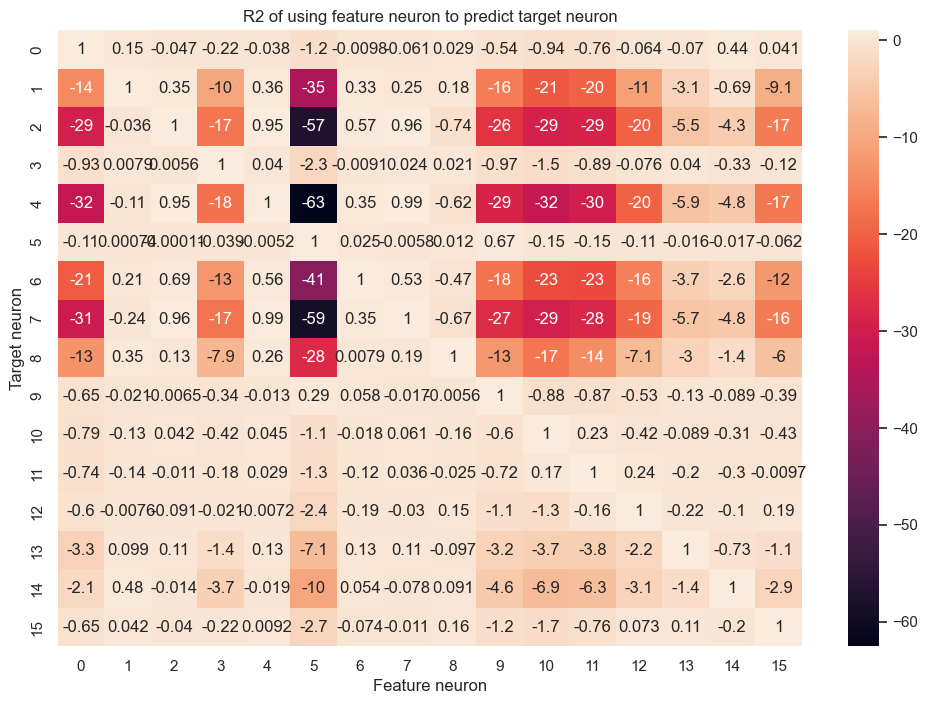

In [ ]:
# How well each neuron can be explained by a single other neuron
# N2, N4, N7 form a gangster

time_step = 7
# Matrix to store R-squared values
r2_matrix = np.zeros((m, m))

# Activations of all neurons at the given time step
activations = activations_dataset[:, time_step, :] @ w_hh.T

# Loop through each pair of neurons
for i in range(m):
    target_activation = activations[:, i]
    for j in range(m):
        if i == j:
            # Skip calculating R-squared for the same neuron (self)
            r2_matrix[i, j] = 1
        else:
            feature_activation = activations[:, j].reshape(-1, 1)

            # Fit linear regression model
            lr_model = LinearRegression(fit_intercept=False)
            lr_model.fit(feature_activation, target_activation)
            predictions = lr_model.predict(feature_activation)

            # Calculate R-squared
            r2 = r2_score(target_activation, predictions)
            r2_matrix[i, j] = r2

# Output the R-squared matrix
plt.figure(figsize=(12, 8))
sns.heatmap(r2_matrix, annot=True)
plt.ylabel('Target neuron')
plt.xlabel('Feature neuron')
plt.title('R2 of using feature neuron to predict target neuron')
plt.show()

R2 can be negtive since we don't include intercepts.

### Neuron Activation Frequency

Nonzero Frequencies for each neuron:
[0.8  0.63 1.   0.69 0.31 0.54 0.59 0.7  0.56 0.28 0.94 0.93 0.98 0.9
 0.88 0.63]


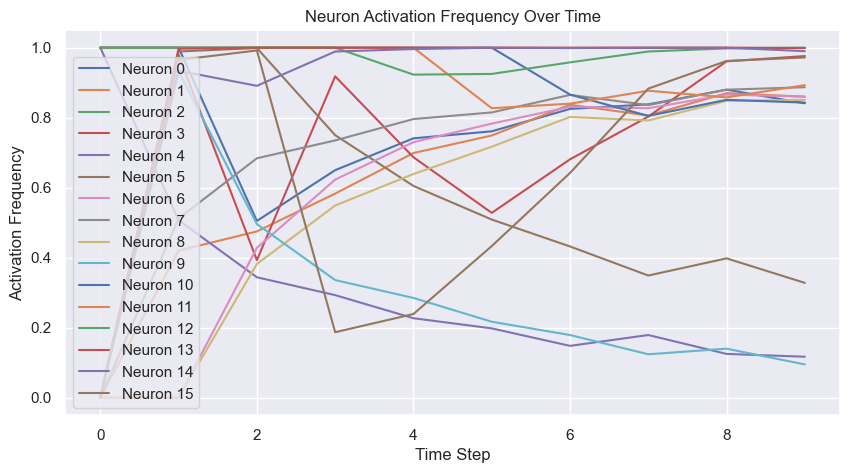

In [ ]:
nonzero_frequencies = calculate_nonzero_frequencies(activations_dataset)
print("Nonzero Frequencies for each neuron:")
print(nonzero_frequencies)

# Calculate the activation frequency: the proportion of non-zero activations per neuron at each time step
activation_frequencies = np.mean(activations_dataset > 0, axis=0)

# Plotting
plt.figure(figsize=(10, 5))
for neuron_idx in range(m):
    plt.plot(activation_frequencies[:, neuron_idx], label=f'Neuron {neuron_idx}')

plt.title('Neuron Activation Frequency Over Time')
plt.xlabel('Time Step')
plt.ylabel('Activation Frequency')
plt.legend()
plt.show()

N9 is actually not really a dead neuron. This can be further confirmed throught ablating it, which results in a 30% accuracy drop.

## Summary

Here we summarize the more definitive findings here, that we will use as hints for constructing a handcoded RNN for this task.

1. We have a few major input neurons N1, N4, N6, N7, N8. The weight for N4 is positive while others are negative.

2. N2 approximately implements max_t, N4 approximately implements ReLU(x_t - max_t) and N7 approximately implements ReLU(max_t - x_t)

3. N8 approximately implements ReLU(2ndmax_t - x_t) in earlier time steps.

4. When calculating the logits at each time t, projecting out the negative input neurons (N1, N6, N7, N8) gives a argmax/max sub-ciruit that is accurate at finding the max index.

5. Overall, at a high level, new values enter through the last logit (m-th) and the previous values (inexactly) shift to ealier logits. For each iteration t, if xt > max_t (running max value), the old max logit gets a boost. Note that this is a restatement of intermediate logits have good accuracies for the running 2nd argmax.

# Hand-coding an almost-perfect RNN


The high level idea is to maintain  set of features, $m_k$ and $s_k$, for representing the scores of each index as the max and the 2nd max index respectively. They correspond to the intermediate logit values and the projected logit values in the trained net. In other words, we have $\arg\max m_k$ is the max index and $\arg \max s_k$ is the 2nd max index at each time step.

When the new input is larger than the running max, i.e., $x_t > \max_t$, we need to update the $s$ value for the argmax logit. Mimicing the trained net, this can be achieved through shifting $m$ values to the $s$ values. We provide two ways of shifting in the code below. The exact shifting is conceptually easier to understand, and the approximate shifting is for the sake of implementing a step function using ReLU. The approximate shifting version can be exactly implemented by a ReLU RNN.


One simple choice of $m_k$ is just $x_k$. The choice of $s_9(x_t)$ is inspired by what the trained RNN, since the sum of N4 and N7 gives $|\max_t- x_t|$, which is partially the weights of logit 9. Note that there is a lot of freedom in the design of $s$ and $m$, we provide a few other options below.




## Algorithm

In [ ]:
def distilled_algo(test_x):
    s = [0 for _ in range(SEQ_LEN)]
    m = [0 for _ in range(SEQ_LEN)]
    max_t = 0
    xt = 0

    for t in range(SEQ_LEN):
        for k in range(9):
            s[k] = s[k+1]
            m[k] = m[k+1]

        # update
        xt = test_x.squeeze()[t]
        m[9] = xt
        s[9] = max_t - abs(max_t - xt)

        # other choices can be
        # m[9] = max_t -  max(xt - max_t, 0)
        # m[9] = max(xt, 0)
        # s[9] = max(max_t - xt, 0)

        # exact shifting version
        if xt > max_t:
            for k in range(9):
                s[k] = m[k]

        # approximate shifting version
        # for k in range(9):
        #     s[k] = m[k] - 2 * max(max_t - xt, 0)
        #                 + 2 * max(max_t - m[k] / 2 + s[k] / 2 - xt, 0)

        max_t = max(xt, max_t)

    return max(enumerate(s), key=lambda x: x[1])[0]


num_samples = 100000
accuracy = 0
for _ in range(num_samples):
    test_x =  torch.rand(1, d, 1, device=device) * 2 - 1
    y = test_x.squeeze().argsort()[-2].item()
    accuracy += (distilled_algo(test_x) == y)
print(accuracy / num_samples)

0.99781



Here we provide an error analysis of the exact shifting version of the distilled algorithm. The approximate shifting can be analyzed similarly.

1. This algorithm computes the argmax when the entire sequence is negative.
2. When exactly one entry of x is positive, then its $s$ will just be -x, it is correct as long as the largest negative number > -x. This has probability 0.9
    - if it is the last entry, then it is correct as long as the largest negative number > -x.
    - if it is not the last entry, the update s[k] <- m[k] doesn't do anything because they are the same anyways, so it is the same case as above.
3. When there are 2 positive entries:
    - if the larger one shows up later, then this guarantees the correctness
    - if the larger one shows up earlier, then this guarantees the correctness too
    
So this algorithm should have accuracy $1 - (2^{-10} + 0.1 * 10 * 2^{-10}) = 0.998$, which matches the empirical accuracy here.

## Hand-coded RNN

The inexact shifting version of the above algorithm can be implemented by an RNN. Here we provide the construction procedure of the net.

The accuracy is 0.9886


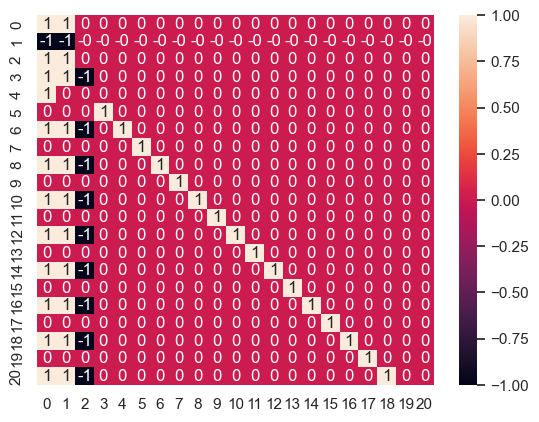

In [ ]:
# construction of w_oh
w_oh = np.zeros((10, 21))
w_oh[9, 0:3] = (1, -1, -1)
for k in range(9):
    w_oh[k, 2] = -2
    w_oh[k, (9-k)*2 + 1] = 1
    w_oh[k, (9-k)*2 + 2] = 2

# construction of w_ih
w_ih = np.zeros((21, 1))
w_ih[1,0] = 1
for k in range(1,11):
    w_ih[2*k] = -1

# construction of w_hh
w_hh = np.zeros((21, 21))
w_hh[0, 0] = 1
w_hh[0, 1] = 1
w_hh[1, :] = -w_hh[0,:]
w_hh[2, :] = w_hh[0, :]
w_hh[3, 0:3] = (1, 1, -1)
w_hh[4, :] = w_hh[0,:] - 0.5 * w_hh[3, :] + 0.5 * w_oh[9, :]

for k in range(5, 20, 2):
    w_hh[k, k-2] = 1
    w_hh[k+1, :] = w_hh[0,:] - 0.5 * w_hh[k, :] + 0.5 * w_oh[int((21 - k)/2), :]

sns.heatmap(w_hh, annot=True)

accuracy_sum = 0
num_samples = 10000

for _ in range(num_samples):
    test_x = torch.rand(1, SEQ_LEN, DIM, device=device) * 2 - 1
    test_x_2nd_max = test_x.squeeze().argsort()[-2].item()

    h_t = np.zeros((21, 1))
    for i in range(10):
        x_i = test_x.squeeze()[i].item()
        h_t = relu(w_hh @ h_t + x_i * w_ih)
    logit = w_oh @ h_t

    accuracy_sum += (logit.argmax() == test_x_2nd_max)

print(f"The accuracy is {accuracy_sum / num_samples}")

Overall, the constructed net and the trained net share similar qualititative patterns. N2, N4 and N7 of the trained net have their exact counterparts in the constucted net. Both nets have a max/argmax sub-circuit. However, there are some major discrepancies:

1. The constructed 21-neuron net has accuracy 99%. In comparison, the trained 16-neuron RNN has accuracy 94% and empirically we found it hard to train a 21-neuron RNN with 95%+ accuracy.

2. Both the constructed and the trained net have 1 major postive entry in the input weight vector $w_{ih}$. However, the constructed net has 10 negative entries, designated to update each of the $s_k$ features. In comparion, the trained net has 4 negative input neurons which seem very entangled and this have been a major obstacle for understanding how $(s_k - m_k)$ is represented.

3. In the constructed net, the $m_k$ features are stored without updates but the max circuit of the trainet net do not store them staticly and or preserve the order. We have similar observations for trained RNN on the argmax task as well.

4. As mentioned above, there are potentially a lot of ways of designing the $s$ and $m$ features. The trained net do not seem to implement the versions described in the code.

